# Independent verifier and constructive heuristics

This notebook restricts analysis to the 14 development instances (`set = dev` in `data/reference/split.csv`) in order to test an independent route verifier against broken plans, evaluate two deterministic constructive baselines relative to SINTEF, and compare them against OR-Tools (Perron & Furnon, 2026) initial constructions without local search.

The `verify` routine recomputes every metric directly from the routes in double precision, checking vehicle capacity, single customer visits, time windows with permitted pre-opening waiting (Toth & Vigo, 2014), depot return within the horizon and fleet limits using exact unrounded Euclidean distances. All metrics reported throughout the project come from this verifier rather than internal solver objective values.

The two baselines represent simple constructive rules: deadline-first greedy sorts customers by window close (earliest-deadline rule; Jackson, 1955) and appends each visit to the first feasible route (first-fit; Johnson, 1974) or opens a new one; time-oriented nearest neighbour (Solomon, 1987) builds routes sequentially by selecting the feasible customer minimising `0.4·distance + 0.4·time_difference + 0.2·urgency`. Because SINTEF adopts a hierarchical fleet-then-distance objective (Bräysy & Gendreau, 2005a; SINTEF, 2008) based on heuristic best known solutions, Δ vehicles is always reported while the distance gap is interpreted strictly when fleets match the reference.

## 1. Environment setup

This section loads the 14 development instances, their corresponding SINTEF references and the frozen development grid (`outputs/frozen/`) through loaders that reject any evaluation instance. The summary table lists the loaded items.

In [1]:
LANG = "en"  # "pt" or "en"

import matplotlib.pyplot as plt
from IPython.display import display

from delivery_routing_vrptw import analysis, benchmark, diagnostics, eda, paths, results, viz_results
from delivery_routing_vrptw.viz import setup_notebook_figures

setup_notebook_figures()

P = paths.data_paths()
R = paths.result_paths()
split = benchmark.read_split(P["split"])
instances, sintef = results.load_dev_instances(P["sintef_zip"], P["sintef_bks"], split)
dev = results.dev_names(split)
grid = results.load_dev_grid(R["dev_grid"], split)

display(eda.localize_columns(analysis.dev_instance_table(instances, sintef), LANG))

,Instance,Family,No. of customers,Capacity (Q),Horizon,SINTEF vehicles,SINTEF distance
0,C103,C1,100,200,1236.0,10,828.06
1,C106,C1,100,200,1236.0,10,828.94
2,C203,C2,100,700,3390.0,3,591.17
3,C206,C2,100,700,3390.0,3,588.49
4,R108,R1,100,200,230.0,9,960.88
5,R110,R1,100,200,230.0,10,1118.84
6,R111,R1,100,200,230.0,10,1096.73
7,R201,R2,100,1000,1000.0,4,1252.37
8,R202,R2,100,1000,1000.0,3,1191.70
9,R207,R2,100,1000,1000.0,2,890.61


### Insight

All 14 development instances with 100 customers each were loaded: two per C series (C103, C106; C203, C206), three per R series (R108, R110, R111; R201, R202, R207) and two per RC series (RC106, RC108; RC203, RC206). Capacities span 200 (series 1), 700 (C2) and 1000 (R2 and RC2), horizons range from 230 (R1) to 3390 (C2) and SINTEF reference fleets run from 2 vehicles (R207) to 11 (RC106). Because this stratified subset covers 14 of 56 instances, it provides a controlled testbed rather than an exhaustive family sample. Before evaluating the baselines, the verifier is tested against deliberately flawed plans.

## 2. The verifier facing broken plans

To verify violation detection, the feasible nearest-neighbour plan on R108 is modified into four defective variants: one customer removed, one customer duplicated and appended to the last route, the earliest-deadline customer moved to the end of another route, and the two heaviest routes merged. The table counts the violations reported per variant.

In [2]:
r108 = instances["R108"]
nn_plan = analysis.baseline_routes(analysis.run_baselines(instances, sintef, ["R108"]), "R108", "nearest_neighbor_tw")
variants = diagnostics.demo_violations(r108, nn_plan)

display(eda.localize_columns(diagnostics.violation_table(r108, variants, LANG), LANG))

,Variant,Feasible,Vehicles,Unserved customers,Repeated customers,Windows violated,Routes over capacity,Late depot returns
0,Original plan (nearest neighbour),True,12,0,0,0,0,0
1,One customer removed,False,12,1,0,0,0,0
2,One customer duplicated,False,12,0,1,1,0,1
3,One customer moved outside its window,False,12,0,0,1,0,0
4,Two routes merged,False,11,0,0,11,1,1


### Insight

The original nearest-neighbour solution on R108 passes cleanly with 12 vehicles, whereas every perturbed variant triggers its expected failure category: the removed customer registers 1 unserved visit; the duplicate registers 1 repeated visit; the shifted customer registers 1 violated window; and the merged route triggers 1 over-capacity route across 11 vehicles. Secondary cascading violations also emerge when schedules stretch: the duplicated late visit triggered 1 window violation and 1 late depot return, while the merged route produced 11 window violations and 1 late return by exceeding the horizon, whereas shifting a single visit violated only that customer's window. Although this single-instance check complements unit tests on synthetic cases rather than proving bug-free code, it confirms that every violation type is caught. Next, both baselines are timed and evaluated across the 14 development instances.

## 3. Baselines on the 14 development instances

The table below compares both constructive heuristics against SINTEF across the 14 instances, displaying reference fleet sizes alongside baseline vehicles, total distance, live runtime (measured via `perf_counter`) and Δ vehicles from the verifier.

In [3]:
baselines = analysis.run_baselines(instances, sintef, dev)

display(eda.localize_columns(analysis.baseline_table(baselines, LANG), LANG))

,Instance,Family,SINTEF vehicles,Deadline-first greedy · Vehicles,Deadline-first greedy · Total distance,Deadline-first greedy · Runtime (s),Deadline-first greedy · Δ vehicles,Nearest neighbour with time windows · Vehicles,Nearest neighbour with time windows · Total distance,Nearest neighbour with time windows · Runtime (s),Nearest neighbour with time windows · Δ vehicles
0,C103,C1,10,12,3472.1,0.0020,2,11,2078.9,0.0237,1
1,C106,C1,10,13,2876.0,0.0021,3,11,1630.9,0.0241,1
2,C203,C2,3,5,3127.5,0.0015,2,4,1765.7,0.0292,1
3,C206,C2,3,4,3070.7,0.0015,1,3,919.6,0.0279,0
4,R108,R1,9,21,3059.1,0.0035,12,12,1324.2,0.0260,3
5,R110,R1,10,19,2668.2,0.0028,9,13,1596.7,0.0251,3
6,R111,R1,10,19,2306.5,0.0027,9,12,1520.8,0.0255,2
7,R201,R2,4,6,2719.2,0.0015,2,5,2150.4,0.0265,1
8,R202,R2,3,5,2598.3,0.0015,2,4,1870.8,0.0270,1
9,R207,R2,2,6,3110.8,0.0016,4,3,1604.3,0.0285,1


### Insight

Both baselines require more vehicles than SINTEF on nearly every instance. Deadline-first greedy adds 1 to 12 extra vehicles (such as 21 against 9 on R108 and 4 against 3 on C206), while nearest neighbour adds 0 to 3 (14 against 11 on RC106; +3 on R108 and R110). Only nearest neighbour on C206 matches the reference fleet (3 vehicles), yet at distance 919.6 against SINTEF's 588.49. Baseline distances span 920 to 3544, well above SINTEF's 589 to 1425, with only C206 directly comparable due to fleet mismatches elsewhere. Execution times stay negligible (under 0.01 s for greedy and under 0.07 s for nearest neighbour), with zero replicate spread because both methods are deterministic and compared against heuristic best known references. The next tables aggregate Δ vehicles by family and check reproducibility against the frozen grid.

To examine behaviour by family and ensure consistency with saved artefacts, the following tables report mean Δ vehicles, feasible solution counts and exact equality checks (vehicles and distance) against the baseline entries stored in the frozen development grid.

In [4]:
display(eda.localize_columns(analysis.baseline_family_summary(baselines, LANG), LANG))
display(eda.localize_columns(analysis.baseline_checks(baselines, grid, LANG), LANG))

,Family,No. of instances,Deadline-first greedy · Mean Δ vehicles,Deadline-first greedy · Feasible,Nearest neighbour with time windows · Mean Δ vehicles,Nearest neighbour with time windows · Feasible
0,C1,2,2.50,2,1.00,2
1,C2,2,1.50,2,0.50,2
2,R1,3,10.00,3,2.67,3
3,R2,3,2.67,3,1.00,3
4,RC1,2,8.00,2,2.50,2
5,RC2,2,3.50,2,1.00,2
6,Total,14,4.93,14,1.50,14


,Indicator,Value
0,Solutions feasible under the verifier,28 / 28
1,Solutions identical to the frozen grid (vehicl...,28 / 28


### Insight

Overall, deadline-first greedy averages +4.93 extra vehicles, ranging from 1.50 in C2 to 10.00 in R1 and 8.00 in RC1, while nearest neighbour averages +1.50, spanning 0.50 (C2) to 2.67 (R1) and 2.50 (RC1). In both methods, series 1 of R and RC (tight windows, short horizons) sit farthest from SINTEF and C2 lies closest, though causal reasons are untested with only two or three instances per family. Both verification checks pass completely: 28 of 28 plans are feasible and match the frozen grid used in notebook 04 in both vehicles and distance. Section 4 compares these baselines against OR-Tools initial constructions without local search.

## 4. Comparison with the OR-Tools constructions without local search

The frozen grid stores the three OR-Tools first-solution strategies executed without metaheuristics (`NONE`) on the same 14 instances. The table and plots compare all five constructive methods by mean Δ vehicles and median distance excess over SINTEF (treated strictly as descriptive when fleets differ from the reference, as tracked by the equal-fleet count column).

,Method,No. of instances,Feasible,Mean Δ vehicles,Median distance excess (%),Instances with fleet equal to reference,"Median gap, equal fleet (%)"
0,Deadline-first greedy,14,14,4.93,213.8,0,-
1,Nearest neighbour with time windows,14,14,1.50,64.3,1,56.3
2,OR-Tools: parallel cheapest insertion (no loca...,14,14,1.86,51.3,1,6.8
3,OR-Tools: path cheapest arc (no local search),14,14,8.36,57.6,0,-
4,OR-Tools: Savings (no local search),14,14,2.79,29.8,0,-


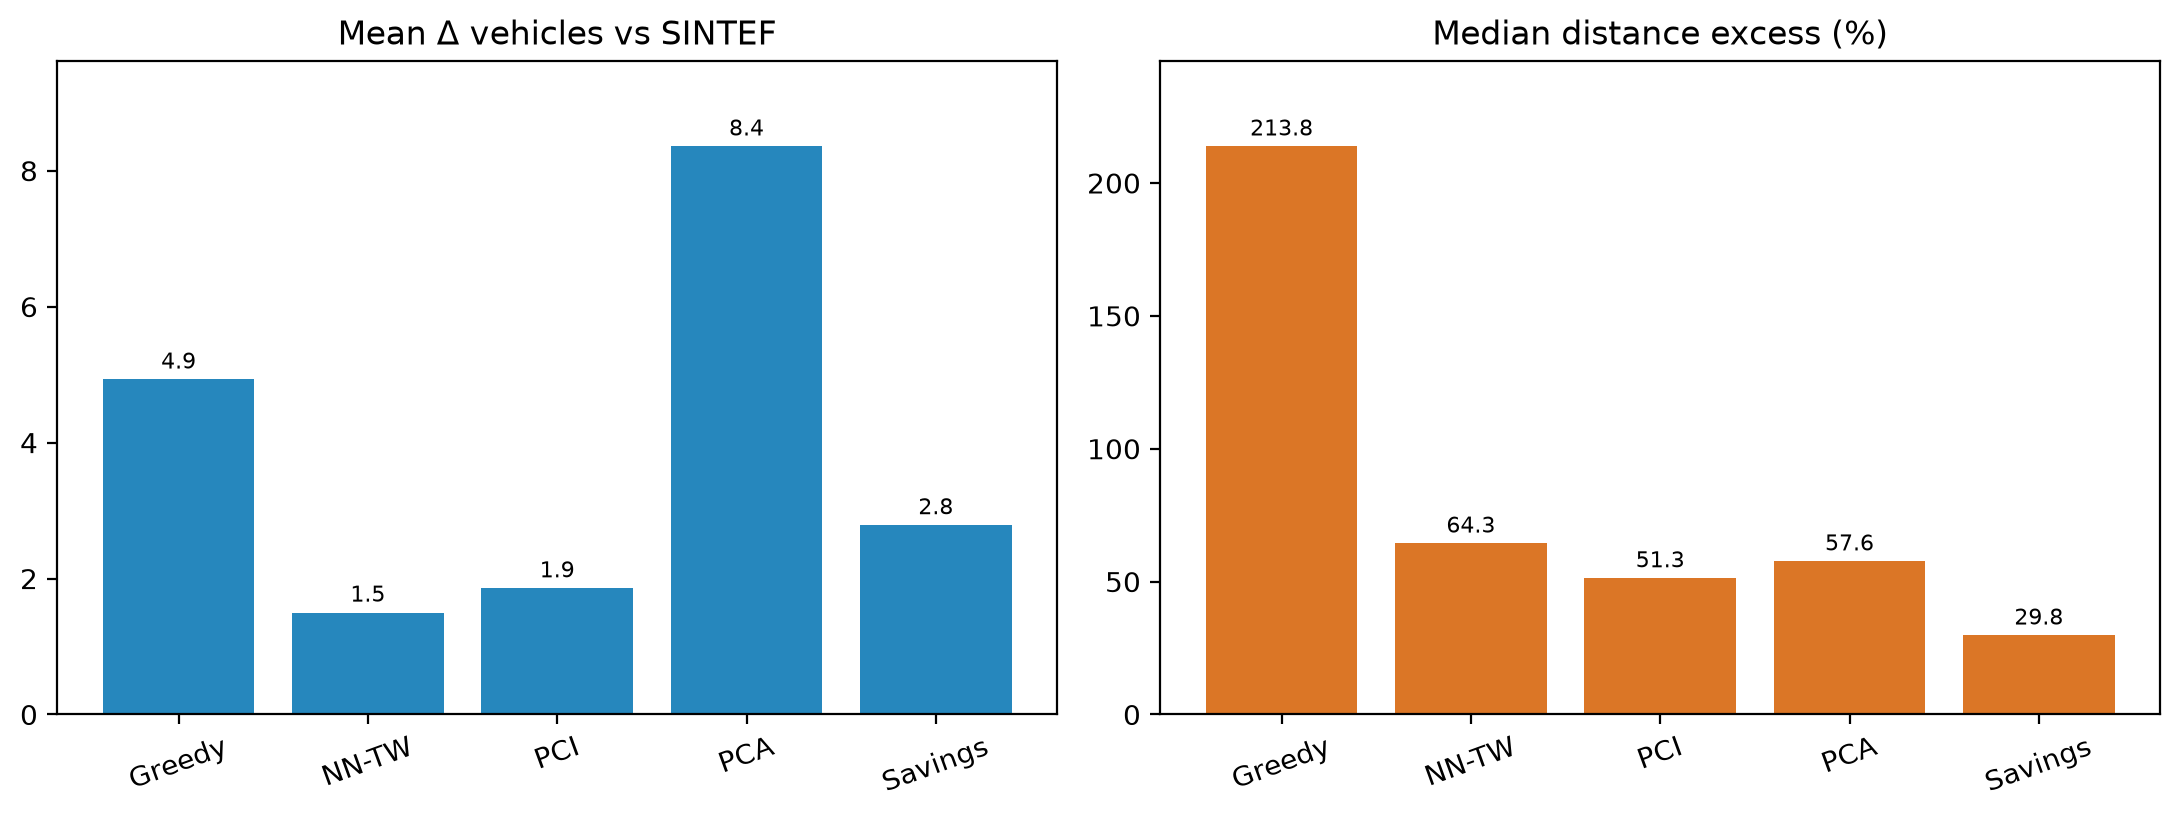

In [5]:
comparison = analysis.construction_comparison(grid, LANG)

display(eda.localize_columns(analysis.construction_table(comparison), LANG))

viz_results.plot_construction_comparison(comparison, LANG)
plt.show()

### Insight

Without local search, all five constructions produce feasible plans on all 14 instances yet swap rankings depending on the criterion. On mean Δ vehicles, nearest neighbour (1.50) and parallel cheapest insertion (1.86) lead Savings (2.79), deadline-first greedy (4.93) and path cheapest arc (8.36). On median distance excess over SINTEF, Savings ranks lowest at 29.8%, followed by parallel insertion (51.3%), path cheapest arc (57.6%), nearest neighbour (64.3%) and greedy (213.8%). Only nearest neighbour and parallel insertion match the reference fleet on a single instance each (with excesses of 56.3% and 6.8%), rendering distance comparisons elsewhere purely descriptive across mismatched fleets. On the primary fleet-size criterion in deterministic runs over 14 instances, nearest neighbour matches or outperforms pure OR-Tools constructions. Next, route geometry is inspected on a clustered instance.

## 5. Route maps for C103

To illustrate spatial differences across constructive heuristics, the plot maps C103 routes built by deadline-first greedy, nearest neighbour and OR-Tools Savings (Clarke & Wright, 1964) without local search, loaded from the frozen grid JSON. Colours distinguish routes, the red square marks the depot and subplot titles show verifier-computed vehicles and distances.

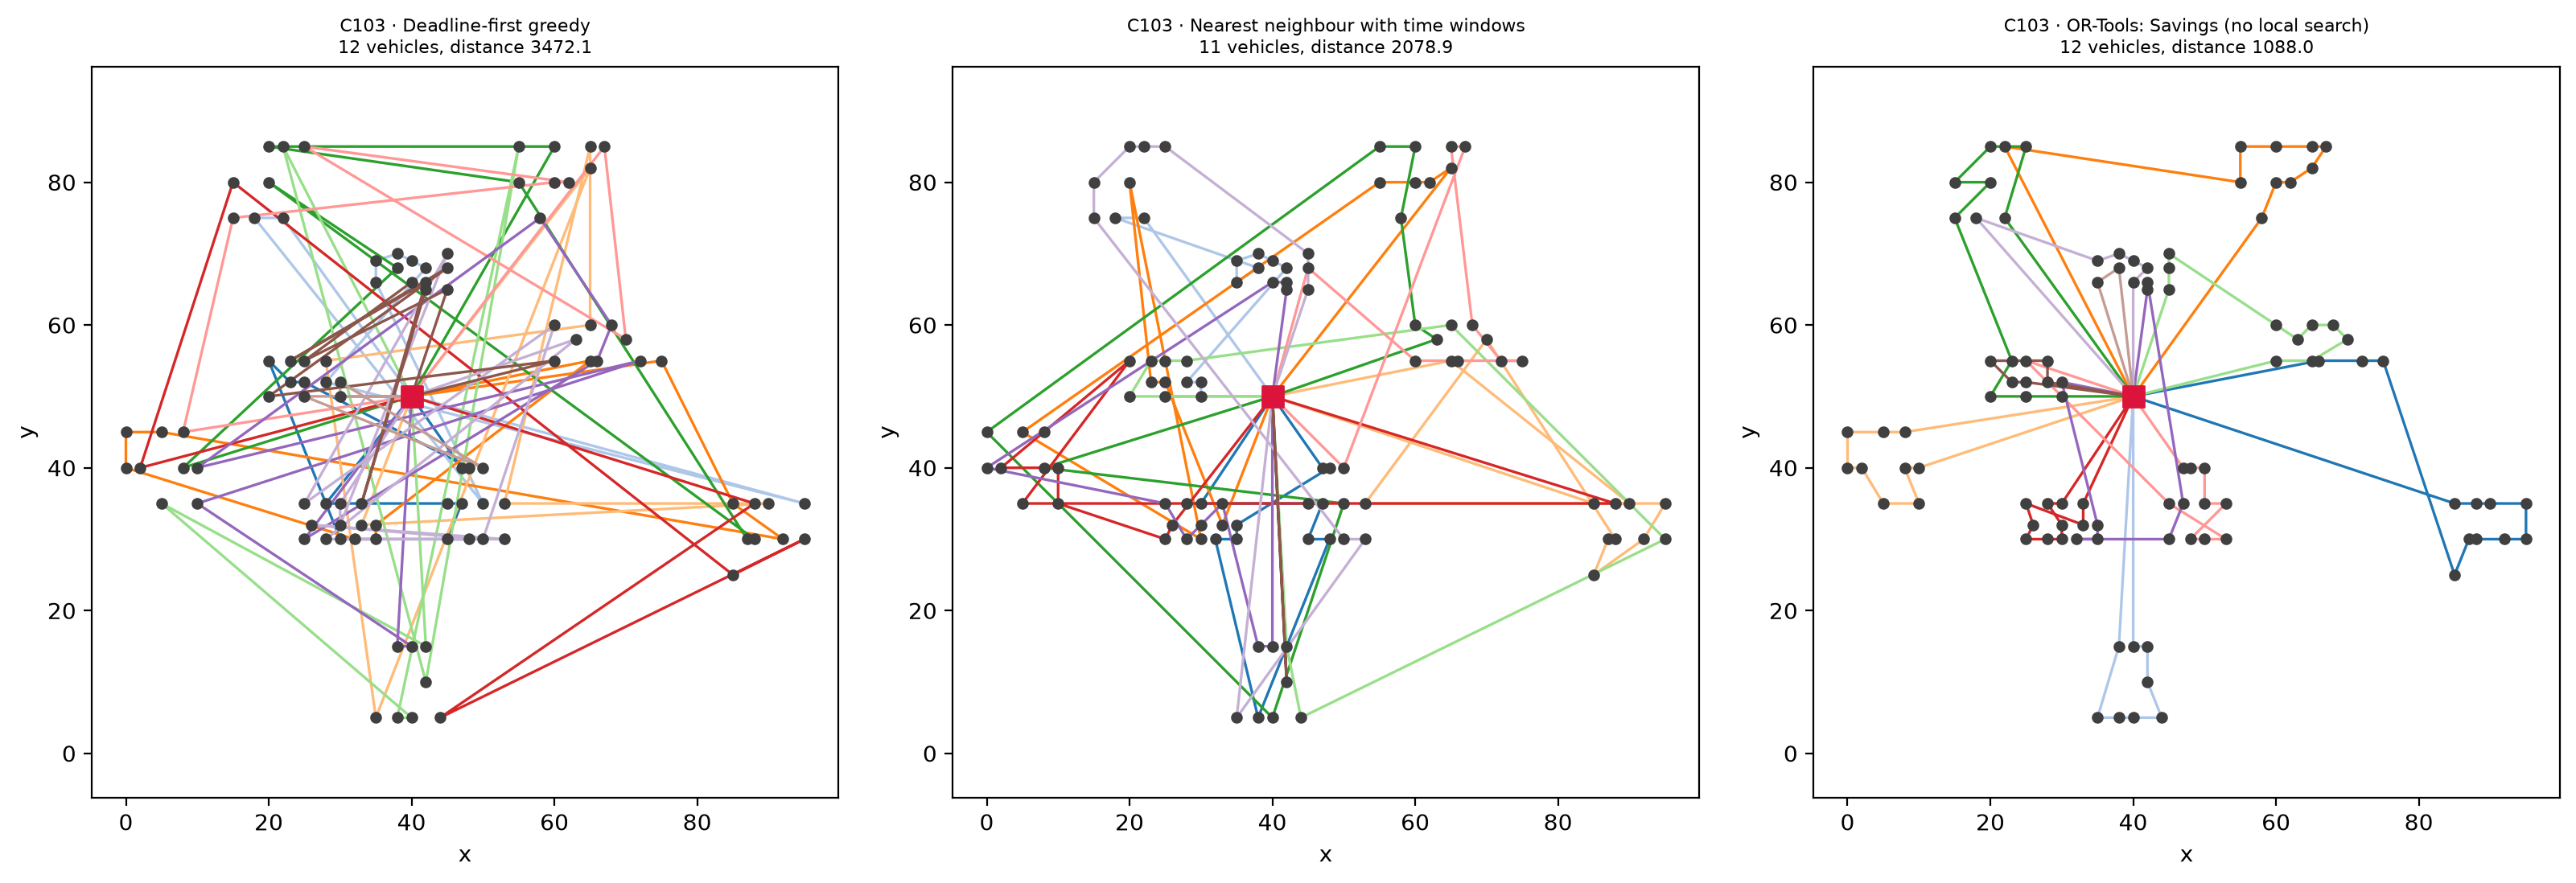

In [6]:
viz_results.plot_route_panels(analysis.baseline_panels("C103", instances, baselines, grid, LANG), LANG)
plt.show()

### Insight

On C103, the three constructions use 11 or 12 vehicles against 10 in the reference: greedy requires 12 vehicles (distance 3472.1), nearest neighbour uses 11 (2078.9) and OR-Tools Savings uses 12 (1088.0). Visually, greedy and nearest neighbour draw long crossing segments connecting distant clusters, whereas Savings routes stay largely confined within single clusters or nearby nodes, matching its much shorter total distance without reducing vehicles relative to nearest neighbour (12 versus 11). This qualitative reading holds for a single instance, with colours carrying no numerical scale. The gains achieved by adding local search are evaluated in notebook 04.

## 6. Synthesis and next step

The independent verifier caught all four injected defect categories (missing customer, duplicate visit, violated window and capacity excess) and supplies every metric used in the project. Across the 14 development instances, both constructive baselines are fully feasible and match the frozen grid exactly, posting mean Δ vehicles of 4.93 (deadline-first greedy) and 1.50 (time-oriented nearest neighbour), with largest gaps in R and RC series 1. Without local search, OR-Tools initial constructions yield mean Δ values of 1.86 (parallel insertion), 2.79 (Savings) and 8.36 (path cheapest arc), matching SINTEF fleet size on at most one instance. Because median distance excess is comparable only under identical fleets, Δ vehicles stays the primary metric.

Notebook 04 proceeds to the pre-registered development tournament, applying local-search metaheuristics to these constructions to select the frozen configuration relative to SINTEF's best known solutions.

## References

- Bräysy, O., & Gendreau, M. (2005a). Vehicle routing problem with time windows, Part I: Route construction and local search algorithms. *Transportation Science, 39*(1), 104–118.
- Clarke, G., & Wright, J. W. (1964). Scheduling of vehicles from a central depot to a number of delivery points. *Operations Research, 12*(4), 568–581.
- Jackson, J. R. (1955). *Scheduling a production line to minimize maximum tardiness* (Research Report 43). Management Science Research Project, University of California, Los Angeles.
- Johnson, D. S. (1974). Fast algorithms for bin packing. *Journal of Computer and System Sciences, 8*(3), 272–314.
- Perron, L., & Furnon, V. (2026). *OR-Tools* (Version 9.15) [Computer software]. Google. https://developers.google.com/optimization/
- SINTEF. (2008). *VRPTW — 100 customers: Solomon benchmark, best known solutions*. SINTEF TOP. https://www.sintef.no/projectweb/top/vrptw/100-customers/
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research, 35*(2), 254–265.
- Toth, P., & Vigo, D. (Eds.). (2014). *Vehicle routing: Problems, methods, and applications* (2nd ed.). SIAM.